# projectile simulation code 

- position: $\vec{r} = (r_x, r_y)$
- velocity: $\vec{v} = (v_x, v_y)$

having newtons second law yields:

$$ m \frac{d \vec{v}}{d t} = \sum \vec{F} $$

two external forces are applied:
- gravity:  $\vec{F}_g = (0, -mg)$
    - $m$: mass of the projectile (considering ball)
    - $g$: local acceleration of free fall = 9.81
- friction*: $\vec{F}_f = -\frac{1}{2} \rho C_d A ||\vec{v}|| \vec{v}$
    - $\rho$: air density
    - $C_d$: drag coefficient
    - $A$: cross-sectional area


*at moderate to high reynolds numbers which covers a ball moving through air.

solvers such as `scipy.integrate.solve_ivp` integrate the systems on the form $\vec{\dot{s}} = \bold{f}(t, \vec{s})$. so the two second order equations become four first-order with $\vec{s}=(r_x, r_y, v_x, v_y)$ we have the system of first order ODE that gives $\vec{\dot{s}} = (\dot{r}_x, \dot{r}_y, \dot{v}_x, \dot{v}_y)$ given by:

$$ 
\boxed{
\begin{aligned}
&    \dot{r}_x = v_x \\
&    \dot{r}_y = v_y \\
&    \dot{v}_x = -\frac{1}{2m} \rho C_d A \sqrt{v_x^2 + v_y^2} \ v_x \\
&    \dot{v}_y = -\frac{1}{2m} \rho C_d A \sqrt{v_x^2 + v_y^2} \ v_y - g \\
\end{aligned}
} $$

and the initial condition is given by $\vec{s}(t = 0)$:

$$
\vec{s}(t = 0) =
\begin{pmatrix}
r_x(t=0) \\
r_y(t=0) \\
v_x(t=0) \\
v_y(t=0) \\
\end{pmatrix}  =
\begin{pmatrix}
0 \\
0 \\
v_0 \cos (\theta) \\
v_0 \sin (\theta) \\
\end{pmatrix}

$$

In [1]:
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import numpy as np

1. initial conditions and constants

In [3]:
theta = np.radians(45)
m = 0.057
r = 0.0325
A = np.pi * r**2 
C_d = 0.47
g = 9.81
rho = 1.225
v0 = 20
initial_position = np.array([0, 0])

initial_velocity = np.array([v0 * np.cos(theta), v0 * np.sin(theta)])
initial_conditions = np.array([initial_position, initial_velocity]).ravel()
initial_conditions

array([ 0.        ,  0.        , 14.14213562, 14.14213562])

2. defining our system of first order ODEs

In [4]:
def system_odes(t, s):
    r_x, r_y, v_x, v_y = s

    dv_x_dt =  -1/2 * rho * C_d * A / m * np.sqrt(v_x**2 + v_y**2) * v_x
    dv_y_dt =  -1/2 * rho * C_d * A / m * np.sqrt(v_x**2 + v_y**2) * v_y - g

    return np.array([v_x, v_y, dv_x_dt, dv_y_dt])

def hit_ground(t, s):
    return s[1] # r_y crosses zero at landing

hit_ground.terminal = True
hit_ground.direction = -1    # only downward crossings, so the start at r_y = 0 is ignored

def apex(t, s):
    return s[3] # v_y, crosses zero at the highest point

apex.direction = -1          # not terminal, it only records


3. solving problem numerically

In [7]:
simulation_time = 100

# Solve the ODE system using solve_ivp
solution = solve_ivp(
    fun=system_odes,        # Function defining the system of ODEs
    t_span=(0, simulation_time),  # Time range for the simulation
    y0=initial_conditions,  # Initial conditions (positions and velocities)
    events=[apex, hit_ground],
    dense_output=True,
    rtol=1e-6,
    atol=1e-6
)

solution

  message: A termination event occurred.
  success: True
   status: 1
        t: [ 0.000e+00  1.584e-02  1.743e-01  4.181e-01  7.192e-01
             1.083e+00  1.502e+00  1.951e+00  2.471e+00  2.563e+00]
        y: [[ 0.000e+00  2.235e-01 ...  2.660e+01  2.735e+01]
            [ 0.000e+00  2.223e-01 ...  1.017e+00  1.332e-15]
            [ 1.414e+01  1.407e+01 ...  8.333e+00  8.158e+00]
            [ 1.414e+01  1.391e+01 ... -1.082e+01 -1.148e+01]]
      sol: <scipy.integrate._ivp.common.OdeSolution object at 0x71e3557e52b0>
 t_events: [array([ 1.223e+00]), array([ 2.563e+00])]
 y_events: [array([[ 1.478e+01,  8.090e+00,  1.059e+01, -1.110e-15]]), array([[ 2.735e+01,  1.332e-15,  8.158e+00, -1.148e+01]])]
     nfev: 62
     njev: 0
      nlu: 0

In [16]:
t_apex, t_land = solution.t_events[0][0], solution.t_events[1][0]
s_apex, s_land = solution.y_events[0][0], solution.y_events[1][0]

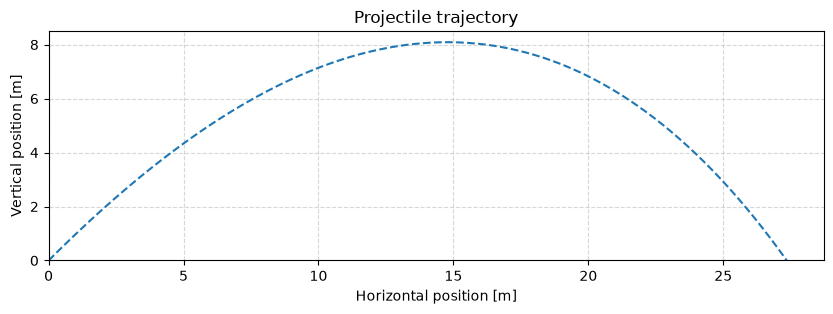

apex reached at t: 1.22 [s], r_y: 8.09 [m]
land reached at t: 2.56 [s], r_x: 27.35 [m]


In [19]:
t_plot = np.linspace(0, t_land, 500)
r_x_sol, r_y_sol, v_x_sol, v_y_sol = solution.sol(t_plot)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(r_x_sol, r_y_sol, linestyle='--', linewidth=1.5)

ax.set_xlabel("Horizontal position [m]")
ax.set_ylabel("Vertical position [m]")
ax.set_title("Projectile trajectory")

ax.set_xlim(left=0)
ax.set_ylim(bottom=0)

ax.set_aspect('equal', adjustable='box')

ax.grid(True, linestyle='--', alpha=0.5)

plt.show()

print(f"apex reached at t: {t_apex:.2f} [s], r_y: {s_apex[1]:.2f} [m]")
print(f"land reached at t: {t_land:.2f} [s], r_x: {s_land[0]:.2f} [m]")

In [18]:
r_x_sol

array([ 0.        ,  0.07256374,  0.14500311,  0.21731877,  0.28951136,
        0.36158153,  0.4335299 ,  0.50535709,  0.57706374,  0.64865046,
        0.72011786,  0.79146656,  0.86269716,  0.93381026,  1.00480647,
        1.07568638,  1.14645059,  1.21709967,  1.28763421,  1.3580548 ,
        1.42836201,  1.49855641,  1.56863857,  1.63860905,  1.70846842,
        1.77821722,  1.84785603,  1.91738537,  1.9868058 ,  2.05611786,
        2.12532208,  2.19441901,  2.26340916,  2.33229306,  2.40107124,
        2.46974423,  2.53831256,  2.60677672,  2.67513723,  2.74339459,
        2.8115493 ,  2.87960186,  2.94755276,  3.01540249,  3.08315154,
        3.1508004 ,  3.21834955,  3.28579947,  3.35315063,  3.42040352,
        3.48755859,  3.55461632,  3.62157717,  3.68844161,  3.7552101 ,
        3.82188308,  3.88846102,  3.95494437,  4.02133356,  4.08762906,
        4.15383129,  4.2199407 ,  4.28595772,  4.35188279,  4.41771634,
        4.48345879,  4.54911056,  4.61467209,  4.68014379,  4.74